# NB4. Integracion termica por franjas del ciclo discontinuo

Este cuaderno cambia de regimen. NB1, NB2 y NB3 operan sobre un proceso continuo, donde todas las corrientes existen al mismo tiempo. En un proceso discontinuo, en cambio, cada corriente existe solo dentro de su franja de operacion, de F1 a F4, y fuera de ella la corriente no aporta ni demanda calor.

Esa discontinuidad obliga a resolver el analisis Pinch franja por franja, con las corrientes activas de cada una, y a integrar despues la energia de las franjas sobre sus duraciones para obtener el ciclo completo. El resultado no es un conjunto de metas independientes: es un perfil de excedente acumulado a lo largo del ciclo.

El perfil entrega la cifra que gobierna el almacenamiento: su amplitud es la cota inferior termodinamica de acumulacion. Por debajo de esa capacidad ningun acumulador cierra el ciclo, porque el ciclo necesita guardar el calor que sobra en unas franjas para cubrir el deficit de otras.

El cuaderno ejecuta los dieciseis pasos de la subseccion 10.4, dibuja sus tres figuras y exporta la tabla horaria de demanda hacia SAM. Cada magnitud impresa es un campo de un objeto devuelto, una clave de un diccionario o un valor de fila del marco cargado. Ninguna celda deriva cifras por diferencias, acumulacion ni rebanado de arreglos.

In [4]:
# Public wheel asset of pre-release v0.2.1, verified by real download: 705792 bytes,
# SHA-256 0861A3AF5E2A5AED69DE236596FD42675B3240ED0AAB9DB18252B84B05CBCA9A.
WHEEL_URL = "https://github.com/iwolde/ship-toolkit-releases/releases/download/v0.2.1/ship_toolkit-0.2.1-py3-none-any.whl"

_REQUIRED = "0.2.1"

import importlib.metadata
import importlib.util
import subprocess
import sys

try:
    _version = importlib.metadata.version("ship-toolkit")
except importlib.metadata.PackageNotFoundError:
    _version = None

if importlib.util.find_spec("ship_toolkit") is None or (
    _version is not None and _version != _REQUIRED
):
    if not WHEEL_URL:
        raise RuntimeError("WHEEL_URL is empty: the wheel has not been published yet.")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", WHEEL_URL], check=True)
    try:
        _version = importlib.metadata.version("ship-toolkit")
    except importlib.metadata.PackageNotFoundError:
        _version = None

if _version is None:
    import ship_toolkit
    _version = getattr(ship_toolkit, "__version__", "sin version")

print("ship-toolkit", _version)

ship-toolkit 0.2.1


## Como se ejecuta este cuaderno

En Colab la celda de preparacion instala el paquete desde el wheel de la pre-release cuando `WHEEL_URL` tiene valor.

Los datos llegan por `data_path` desde el paquete instalado. No se sube ningun archivo a mano y no se lee de Google Drive.

En ejecucion local desde el repositorio la celda de preparacion no instala nada.

In [6]:
from pathlib import Path
import tempfile

from ship_toolkit import (
    apply_style,
    data_path,
    load_sam_continuous_csv,
    load_streams,
    plot_daily_dispatch,
    plot_surplus_profile,
)
from ship_toolkit.cycle import (
    BatchReference,
    build_intervals,
    interval_duration_h,
    run_cycle,
    storage_lower_bound,
    surplus_profile,
)
from ship_toolkit.hen_teaching import build_slice_hens, plot_slice_hens
from ship_toolkit.sam import batch_day_report, sam_input_table, write_sam_input

apply_style()

## Las cuatro franjas del lote

Cada franja del lote tiene su propio archivo de corrientes, con dos corrientes por franja. La sintesis de red por etapa se resuelve con `build_slice_hens`, que recibe el diccionario de corrientes por etiqueta y devuelve una red por franja con su consumo de servicio caliente, su consumo de servicio frio, el defecto de teselado geometrico de su registro de intercambios y la carga transferida a traves del pliegue.

El servicio auxiliar es una decision de diseno y no una constante universal, de modo que se declara en la llamada. El servicio caliente de 140.0 C supera los cuatro objetivos frios mayores, que son 69.0, 64.0, 49.0 y 69.0 C, y el servicio frio de 10.0 C queda por debajo de los cuatro objetivos calientes menores, que son 34.0, 39.0, 29.0 y 29.0 C. El criterio de admisibilidad se cumple por tanto en las cuatro franjas, tal como declara la nota de la subseccion 10.4.

La sintesis se ejecuta con pliegue respetado, de modo que las cargas de servicio de cada red deben coincidir con las metas de la cascada de calor de su franja y no con una asignacion geometrica libre.

In [8]:
streams_by_label = {
    "F1": load_streams(data_path("c53_batch_streams_F1.csv")),
    "F2": load_streams(data_path("c53_batch_streams_F2.csv")),
    "F3": load_streams(data_path("c53_batch_streams_F3.csv")),
    "F4": load_streams(data_path("c53_batch_streams_F4.csv")),
}
slice_hens = build_slice_hens(
    streams_by_label,
    dT_min_K=10.0,
    t_hot_service_C=140.0,
    t_cold_service_C=10.0,
    respect_pinch=True,
)

In [9]:
print("Servicio por franja, red sintetizada con pliegue respetado")
for etiqueta, red in slice_hens.items():
    print(
        f"  {etiqueta}"
        f"  Qh {red.Qh_kW:.1f} kW"
        f"  Qc {red.Qc_kW:.1f} kW"
        f"  defecto de teselado {red.closure_kW:.1f} kW"
        f"  cruce de pliegue {red.cross_pinch_kW:.1f} kW"
    )
print(
    f"F1 exige {slice_hens['F1'].Qh_kW:.1f} kW de servicio caliente y"
    f" {slice_hens['F1'].Qc_kW:.1f} kW de servicio frio,"
    f" con defecto de teselado de {slice_hens['F1'].closure_kW:.1f} kW"
    f" y cruce de pliegue de {slice_hens['F1'].cross_pinch_kW:.1f} kW"
)
print(
    f"F3 no exige servicio caliente ({slice_hens['F3'].Qh_kW:.1f} kW)"
    f" y evacua {slice_hens['F3'].Qc_kW:.1f} kW de servicio frio"
)

Servicio por franja, red sintetizada con pliegue respetado
  F1  Qh 43.5 kW  Qc 0.0 kW  defecto de teselado 0.0 kW  cruce de pliegue 0.0 kW
  F2  Qh 3.0 kW  Qc 12.0 kW  defecto de teselado 0.0 kW  cruce de pliegue 0.0 kW
  F3  Qh 0.0 kW  Qc 24.0 kW  defecto de teselado 0.0 kW  cruce de pliegue 0.0 kW
  F4  Qh 42.0 kW  Qc 3.0 kW  defecto de teselado 0.0 kW  cruce de pliegue 0.0 kW
F1 exige 43.5 kW de servicio caliente y 0.0 kW de servicio frio, con defecto de teselado de 0.0 kW y cruce de pliegue de 0.0 kW
F3 no exige servicio caliente (0.0 kW) y evacua 24.0 kW de servicio frio


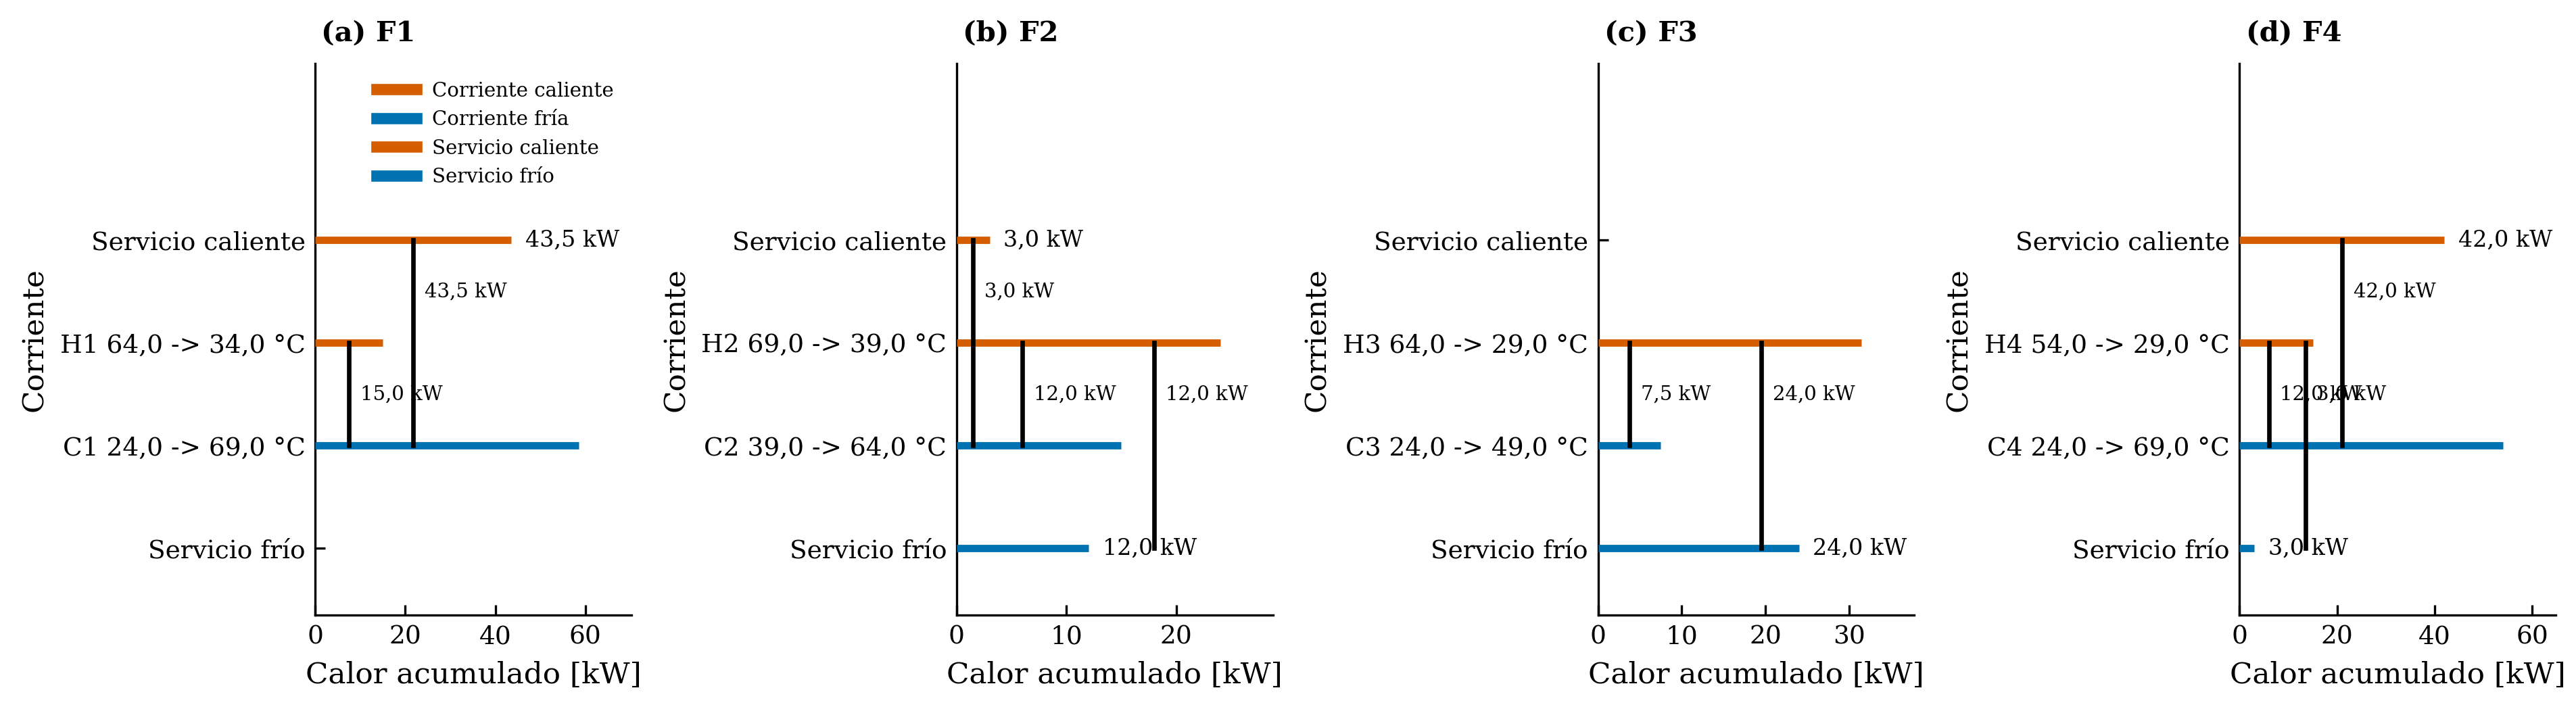

In [10]:
fig_intervals = plot_slice_hens(slice_hens, stage_streams=streams_by_label)

## Del estado por franja al ciclo completo

La red por franja describe un instante de operacion. El ciclo necesita ademas la duracion de cada franja, porque una meta de potencia solo se convierte en energia cuando se multiplica por el tiempo durante el cual esa potencia se sostiene.

`build_intervals` construye la secuencia tipada de intervalos a partir del mismo diccionario de corrientes y de un diccionario de duraciones. Cada intervalo porta su etiqueta, su duracion, sus corrientes y las dos sumas de capacidad termica por lado, de modo que la celda no suma corrientes a mano.

`run_cycle` resuelve la cascada de calor de cada etapa por separado e integra los balances del ciclo. La energia de servicio caliente y la de servicio frio se obtienen de las metas de cada etapa ponderadas por su duracion, la potencia media de calefaccion se obtiene del cociente entre la energia y la duracion total, y el residuo de Primera Ley acumulado compara esas metas contra el balance entalpico de las corrientes. Ese residuo es falsable: si las etapas registradas no describen las corrientes registradas, deja de estar dentro de la tolerancia.

In [12]:
intervals = build_intervals(
    streams_by_label,
    durations_h={"F1": 2.5, "F2": 2.0, "F3": 2.0, "F4": 1.5},
)
primer_intervalo = intervals[0]
duraciones_h = tuple(interval_duration_h(interval) for interval in intervals)
cycle = run_cycle(intervals, dT_min_K=10.0, dt_cont_K=5.0)

In [13]:
print("Primer intervalo del ciclo")
print(f"  duracion            {primer_intervalo.duration_h:.1f} h")
print(f"  suma CP lado caliente {primer_intervalo.hot_CP_sum_kW_per_K:.1f} kW/K")
print(f"  suma CP lado frio     {primer_intervalo.cold_CP_sum_kW_per_K:.1f} kW/K")
print("Tabla de intervalos del ciclo")
print("  etiqueta  duracion_h  CP_caliente_kW_per_K  CP_frio_kW_per_K")
for intervalo in intervals:
    print(
        f"  {intervalo.label:>8}"
        f"  {intervalo.duration_h:>10.1f}"
        f"  {intervalo.hot_CP_sum_kW_per_K:>21.1f}"
        f"  {intervalo.cold_CP_sum_kW_per_K:>16.1f}"
    )
print(f"Duraciones en orden: {duraciones_h} h")
print("Integracion del ciclo")
print(f"  duracion total        {cycle.total_duration_h:.1f} h")
print(f"  energia de servicio caliente {cycle.total_heating_energy_kWh:.2f} kWh")
print(f"  energia de servicio frio     {cycle.total_cooling_energy_kWh:.2f} kWh")
print(f"  potencia media de calefaccion {cycle.mean_heating_power_kW:.5f} kW")
print(f"  residuo de Primera Ley {cycle.energy_residual_kWh:.2e} kWh")
print(f"  cierre del ciclo      {cycle.closes}")

Primer intervalo del ciclo
  duracion            2.5 h
  suma CP lado caliente 0.5 kW/K
  suma CP lado frio     1.3 kW/K
Tabla de intervalos del ciclo
  etiqueta  duracion_h  CP_caliente_kW_per_K  CP_frio_kW_per_K
        F1         2.5                    0.5               1.3
        F2         2.0                    0.8               0.6
        F3         2.0                    0.9               0.3
        F4         1.5                    0.6               1.2
Duraciones en orden: (2.5, 2.0, 2.0, 1.5) h
Integracion del ciclo
  duracion total        8.0 h
  energia de servicio caliente 177.75 kWh
  energia de servicio frio     76.50 kWh
  potencia media de calefaccion 22.21875 kW
  residuo de Primera Ley -3.55e-15 kWh
  cierre del ciclo      True


## Perfil de excedente, cota de almacenamiento y lote de referencia

El ciclo cerrado entrega tres objetos distintos y no tres cifras sueltas.
`surplus_profile` devuelve el perfil de calor acumulado respecto de la media del ciclo, con su discretizacion temporal y las dos series del perfil. Su amplitud es la diferencia entre el maximo y el minimo de esa acumulacion. El valor terminal del perfil es una identidad de la normalizacion respecto de la media y no un indicador de cierre fisico, de modo que el perfil no declara cierre ciclico y no se imprime uno.

`storage_lower_bound` lee la amplitud del perfil y la devuelve como capacidad neta util indispensable de almacenamiento termico. Es una cota termodinamica y no un dimensionamiento: no incluye perdidas del estanque, estratificacion ni margen de diseno.

`BatchReference` es el registro de referencia del lote y calcula su propia energia diaria. La masa diaria de extraccion, el salto termico nominal y el calor especifico se declaran, y la energia diaria de referencia sale del producto de los tres dentro del registro, sin multiplicacion en celda.

In [15]:
profile = surplus_profile(cycle)
bound = storage_lower_bound(cycle)
referencia_lote = BatchReference(
    draw_mass_kg_per_day=500.0,
    nominal_dT_K=50.0,
    cp_kJ_per_kg_K=4.18,
)

In [16]:
print("Perfil de excedente del ciclo")
print(f"  amplitud              {profile.amplitude_kWh:.6f} kWh")
print(f"  maximo acumulado      {profile.max_surplus_kWh:.6f} kWh")
print(f"  minimo acumulado      {profile.min_surplus_kWh:.6f} kWh")
print(f"  hora del maximo       {profile.time_max_h:.1f} h")
print(f"  hora del minimo       {profile.time_min_h:.1f} h")
print("Cota inferior termodinamica de almacenamiento")
print(f"  capacidad             {bound.capacity_kWh:.6f} kWh")
print("Registro de referencia del lote")
print(f"  extraccion diaria     {referencia_lote.draw_mass_kg_per_day:.1f} kg/d")
print(f"  salto termico nominal {referencia_lote.nominal_dT_K:.1f} K")
print(f"  calor especifico      {referencia_lote.cp_kJ_per_kg_K:.2f} kJ/(kg K)")
print(f"  energia diaria        {referencia_lote.daily_energy_kWh:.4f} kWh")

Perfil de excedente del ciclo
  amplitud              82.875000 kWh
  maximo acumulado      53.203125 kWh
  minimo acumulado      -29.671875 kWh
  hora del maximo       2.5 h
  hora del minimo       6.5 h
Cota inferior termodinamica de almacenamiento
  capacidad             82.875000 kWh
Registro de referencia del lote
  extraccion diaria     500.0 kg/d
  salto termico nominal 50.0 K
  calor especifico      4.18 kJ/(kg K)
  energia diaria        29.0278 kWh


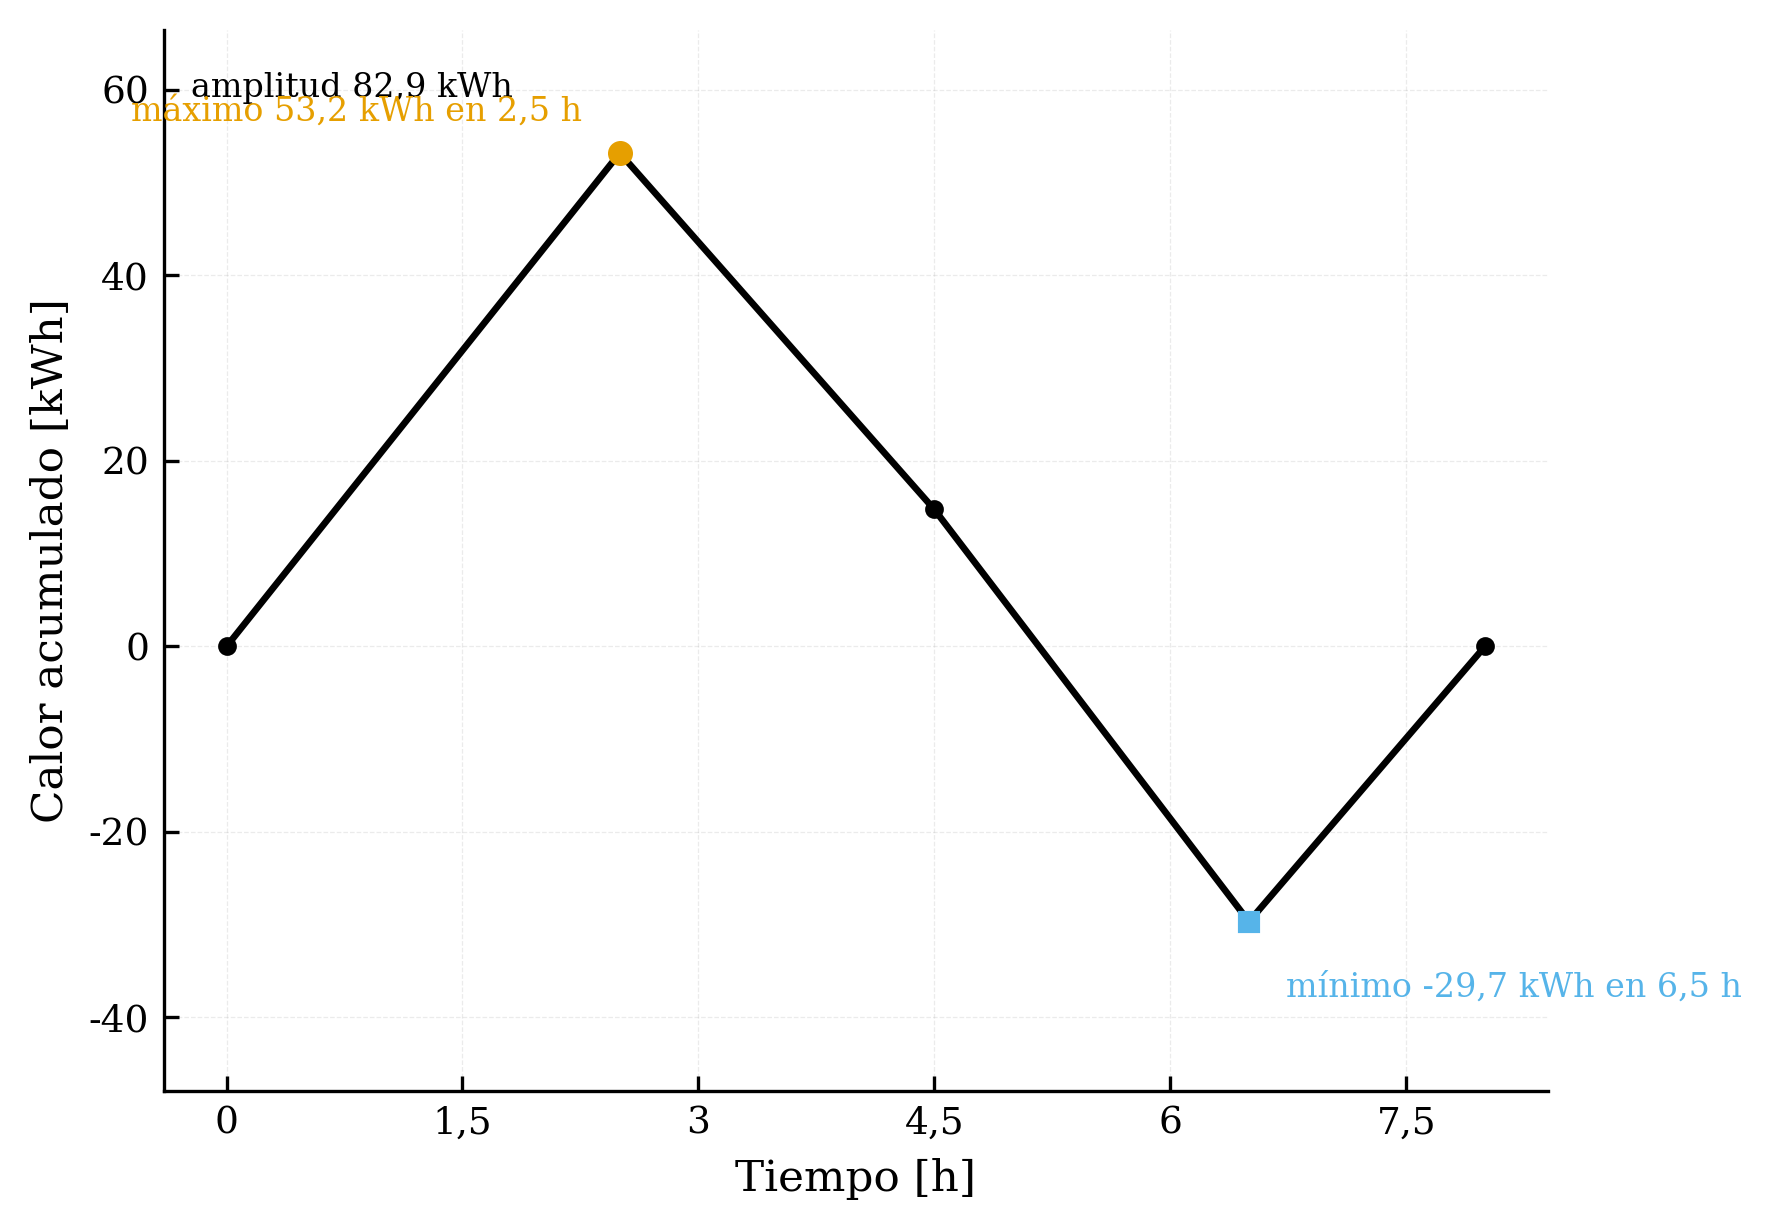

In [17]:
fig_surplus = plot_surplus_profile(profile)

## La proyeccion horaria y la ventana de despacho del lote

Las franjas describen el proceso. La proyeccion solar horaria describe el sistema que lo alimenta, y en este cuaderno esa proyeccion se lee del archivo continuo de SAM con `load_sam_continuous_csv`, igual que en NB3. NB4 no carga archivo climatico ni dimensiona campo solar: el dimensionamiento del campo pertenece a NB3 y aqui solo se consume su resultado horario.

`batch_day_report` resume la jornada sin acumulacion en celda. La columna de energia del sistema y la columna de referencia se declaran en la llamada, porque el archivo continuo nombra esas dos potencias de forma distinta a la del archivo por lotes. La referencia se integra sobre field_leaving_kW, la potencia termica que abandona el campo solar, y no sobre una columna de demanda util: el archivo continuo no expone una columna de consumo, de modo que la referencia es la oferta del campo y se rotula como tal.

La ventana de despacho del lote es un dia de veinticuatro horas y no el ano completo, de modo que `plot_daily_dispatch` resuelve sus dos cargas por la tabla de precedencia de columnas del productor.

El cierre del cuaderno exporta la tabla horaria de demanda en el formato que consume SAM. La exportacion escribe en un directorio temporal fuera del repositorio y el archivo se elimina inmediatamente despues, de modo que el arbol de trabajo queda sin residuos y el cuaderno es reproducible. La tabla se imprime por sus tres primeras filas para mostrar su estructura de columnas.

In [19]:
sam_batch = load_sam_continuous_csv(data_path("c53_results_continuous.csv"))
report_dia = batch_day_report(
    sam_batch,
    energy_column="sink_kW",
    reference_column="field_leaving_kW",
)

In [20]:
print("Resumen de la jornada del lote")
print(f"  referencia sobre field_leaving_kW {report_dia.reference_demand_kWh:.4f} kWh")
print(f"  energia entregada     {report_dia.delivered_energy_kWh:.4f} kWh")
print(f"  potencia minima       {report_dia.daily_min_kW:.4f} kW")
print(f"  potencia maxima       {report_dia.daily_max_kW:.4f} kW")
print(f"  horas nulas           {report_dia.null_hours_h:.1f} h")
print("Primera fila del marco cargado")
print(f"  sink_kW               {sam_batch['sink_kW'].iloc[0]:.4f} kW")
print(f"  field_leaving_kW      {sam_batch['field_leaving_kW'].iloc[0]:.4f} kW")

Resumen de la jornada del lote
  referencia sobre field_leaving_kW 939343.4990 kWh
  energia entregada     876222.5207 kWh
  potencia minima       0.0000 kW
  potencia maxima       215.1050 kW
  horas nulas           4341.0 h
Primera fila del marco cargado
  sink_kW               215.0020 kW
  field_leaving_kW      0.0000 kW


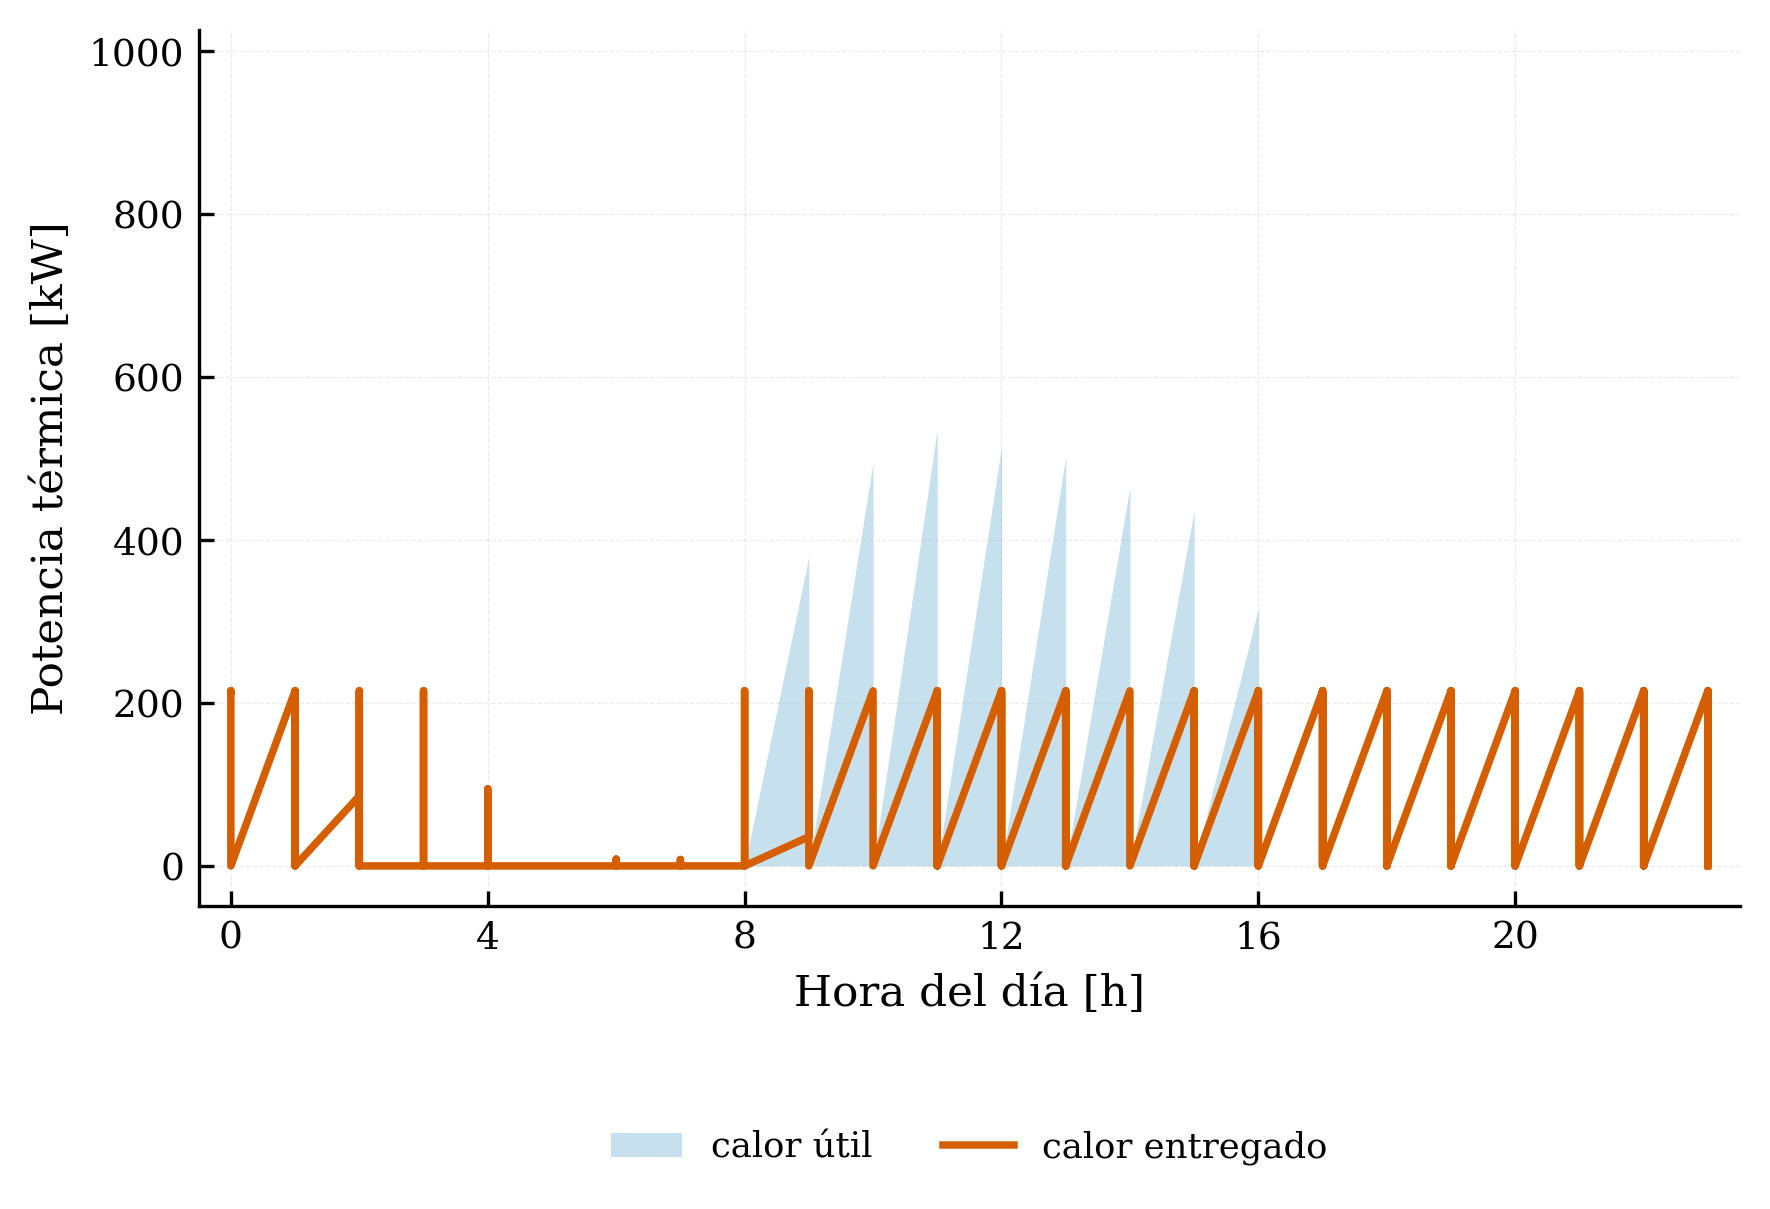

In [21]:
fig_dispatch_batch = plot_daily_dispatch(sam_batch)

In [22]:
streams = streams_by_label["F1"]
sam_input_frame = sam_input_table(
    streams,
    profile_hourly_kW=sam_batch["sink_kW"],
)
target_csv = Path(tempfile.gettempdir()) / "sam_load_input.csv"
written_path = write_sam_input(sam_input_frame, target_csv)
print(f"Archivo exportado: {written_path.name}")
print(f"Columnas: {tuple(sam_input_frame.columns)}")
print(sam_input_frame.head(3).to_string(index=False))
target_csv.unlink(missing_ok=True)

Archivo exportado: sam_load_input.csv
Columnas: ('hour', 'hour_of_day', 'demand_kW', 'htf_mass_flow_kg_s', 'dt_nominal_K', 'cp_kJ_kgK')
 hour  hour_of_day  demand_kW  htf_mass_flow_kg_s  dt_nominal_K  cp_kJ_kgK
    1            0   215.0020            5.143589          10.0       4.18
    2            1   215.0020            5.143589          10.0       4.18
    3            2    85.9957            2.057313          10.0       4.18


In [ ]:
# Export batch del paquete de la Tarea 5: results_batch.csv viaja con el material
# del curso y no dentro del wheel. ship_toolkit/data publica nueve archivos y
# ninguno de ellos es este export.
#
# No se abre por ruta relativa: en Colab el directorio de trabajo es /content y
# el archivo no esta alli. Se busca el export en el paquete de la Tarea 5, se lee
# a memoria y se entrega al cargador como BytesIO, de modo que el resultado no
# dependa del directorio de trabajo.
from io import BytesIO

from ship_toolkit.sam import load_sam_batch_csv

NOMBRE_EXPORT = "results_batch.csv"
FUENTES_EXPORT = (
    ("junto al cuaderno", Path.cwd() / NOMBRE_EXPORT),
    ("carpeta datos del cuaderno", Path.cwd() / "datos" / NOMBRE_EXPORT),
    ("carpeta datos de /content", Path("/content") / "datos" / NOMBRE_EXPORT),
)

RUTA_EXPORT = None
ORIGEN_EXPORT = None
for etiqueta, ruta in FUENTES_EXPORT:
    if ruta.is_file():
        RUTA_EXPORT, ORIGEN_EXPORT = ruta, etiqueta
        break

if RUTA_EXPORT is None:
    raise FileNotFoundError(
        f"No se encontro {NOMBRE_EXPORT}. Fuentes intentadas: "
        + ", ".join(str(ruta) for _, ruta in FUENTES_EXPORT)
        + ". El export viaja en el paquete de la Tarea 5, no en el wheel. "
        "Descargalo del material del curso, colocalo junto a este cuaderno "
        "o en una carpeta datos/ hermana, y vuelve a ejecutar la celda."
    )

batch_export = load_sam_batch_csv(BytesIO(RUTA_EXPORT.read_bytes()))
print(f"Export cargado: {NOMBRE_EXPORT} ({ORIGEN_EXPORT})")

UNIDADES_BATCH = {
    "hour": "h",
    "hour_of_day": "h",
    "draw_kg_hr": "kg/h",
    "q_useful_kW": "kW",
    "q_delivered_kW": "kW",
    "q_auxiliary_kW": "kW",
    "q_loss_kW": "kW",
    "q_transmitted_kW": "kW",
    "power_generated_kW": "kW",
    "p_pump_kW": "kW",
    "t_delivered_C": "C",
    "t_mains_C": "C",
    "t_tank_C": "C",
    "beam_W_m2": "W/m2",
    "v_cold_m3": "m3",
}

print("Columnas del export batch, con su unidad")
for columna in batch_export.columns:
    print(f"  {columna:<22} {UNIDADES_BATCH[columna]}")

print()
print("El estanque trae una sola temperatura, t_tank_C.")
print("No hay nodos caliente y frio del estanque en este export.")

In [ ]:
# Energia almacenada y estado de carga a partir de la temperatura unica del estanque.
RHO_KG_M3 = 980.0
CP_KJ_KGK = 4.186
VOLUMEN_TES_M3 = 50.0  # Volumen declarado de diseno para este ejemplo.
T_COLD_DISENO_C = 20.0
T_HOT_DISENO_C = 99.0

energia_almacenada_kWh = (
    RHO_KG_M3 * VOLUMEN_TES_M3 * CP_KJ_KGK
    * (batch_export["t_tank_C"] - T_COLD_DISENO_C) / 3600.0
)
soc = (
    (batch_export["t_tank_C"] - T_COLD_DISENO_C)
    / (T_HOT_DISENO_C - T_COLD_DISENO_C)
)
energia_util_ciclo_kWh = energia_almacenada_kWh.max() - energia_almacenada_kWh.min()

print(f"SOC minimo {soc.min():.6f}")
print(f"SOC maximo {soc.max():.6f}")
print(f"Energia util del ciclo {energia_util_ciclo_kWh:.4f} kWh")
print()
print("T hot y T cold son la entrada y la salida del lazo de colectores,")
print("no los nodos del estanque. El estanque tiene una sola temperatura, t_tank_C.")


## Que ensena este cuaderno

El analisis por franjas y el ciclo integrado no son la misma pregunta. La red de la franja F1 exige 43.5 kW de servicio caliente y la de F3 no exige servicio caliente y evacua 24.0 kW de servicio frio, y esas dos cifras no se suman entre si porque no ocurren al mismo tiempo. La lectura del ciclo las convierte en energia al ponderarlas por 2.5 h, 2.0 h, 2.0 h y 1.5 h: 177.75 kWh de servicio caliente y 76.5 kWh de servicio frio en 8.0 h, con una potencia media de calefaccion de 22.21875 kW y un residuo de Primera Ley acumulado de -3.55e-15 kWh, dentro de la tolerancia declarada.

La amplitud del perfil de excedente, 82.875 kWh, es la cota inferior termodinamica de almacenamiento del ciclo. Se lee como condicion necesaria y no como dimensionamiento: un acumulador menor no puede cerrar el ciclo, y uno mayor no queda justificado por esta cifra, que ignora perdidas, estratificacion y margen de diseno. El lote de referencia de 500.0 kg/d con salto nominal de 50.0 K y calor especifico de 4.18 kJ/(kg K) pide 29.0278 kWh al dia, de modo que la cota del ciclo es muy superior a la energia diaria de extraccion y responde a la forma del perfil y no a su nivel medio.

La demanda horaria se exporta en el formato de SAM y la ventana de despacho del lote se dibuja sobre un dia de veinticuatro horas. El resumen diario entrega 876222.5207 kWh de energia entregada frente a 939343.4990 kWh de referencia integrada sobre la salida del campo (field_leaving_kW), con 4341.0 horas nulas en el ano horario, y las dos cifras se leen del reporte y no se derivan en celda.